# 05c — Spatial gating with designed waves

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/05c_analog_brain_waves.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

Activity can change because a network learns new weights, because its input changes, or because a control signal gates an existing input. This notebook isolates the third possibility using a designed one-dimensional sheet. Two object-related drives are multiplied by spatial suppression patterns. Changing the pattern changes which activity is expressed, with no weight learning.

The later panels combine prescribed control waves and move an open window across the sheet. This lets you distinguish a changed drive, a changed gate and a changed learned parameter by following their separate roles in the equations.

### Learning goals

1. Distinguish a drive, a suppression stencil and the resulting expressed activity.
2. Explain how a fixed unit's selectivity can depend on context without weight changes.
3. Separate arithmetic superposition from a learned control policy.
4. Identify the missing measurements needed for a physiological interpretation.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

A **drive** is the activity profile offered by an input. A **stencil** is a spatial control pattern: one means fully suppressed and zero means open. **Expressed activity** is the part of the drive that remains after gating. The same drive can therefore produce different responses when the context changes.

**Mixed selectivity** means a unit's response depends on a combination of variables, such as object and context. Here that dependence is constructed from overlapping drive and stencil curves. The marked units are selected by a rule designed to illustrate relatively stable and context-sensitive responses; they are not an unbiased sample of recorded cells.

**Traveling window** means that the allowed activity region moves with time. It changes the location at which a broad drive is expressed. It does not, in this code, transport a learned memory or derive the control signal from a task.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

For drive $d(x)$ and suppression $s_c(x)\in[0,1]$ in context $c$,

$$r(x,c)=d(x)[1-s_c(x)].$$

The context interaction follows directly from multiplication. There is no fitted weight matrix in this equation. The four combined control curves are arithmetic means of two prescribed waves, not the outputs of a learned composition rule.

The moving-window example uses $r(x,t)=d(x)g(x,t)$ with a Gaussian open gate whose center is prescribed in time. The space–time panel displays this product on dimensionless axes. A physiological wave model would additionally specify dynamics that generate the gate, physical units and an observation model linking it to recorded signals.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.analog_waves import (
    combine_waves,
    control_waves,
    expressed,
    object_drives,
    positions,
    render_paper_figure,
    run_experiment,
    selectivity_table,
    traveling_movie,
    traveling_open,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)


Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7


## A stencil, two objects, two contexts

Object A and object B are two feedforward bumps on a 1-D sheet. Context *first* closes the right side; context *second* closes the mid-sheet. Expressed activity is drive $\times$ open. No weight is updated. Unit 1 sits where both stencils are weak and keeps an object-A preference. Unit 2 sits where the stencil covers object B in one context and opens it in the other.

**Before running.** Pick one sheet position and compare its four object-by-context values. Identify whether a response difference comes from the object drive or the stencil at that location. The two highlighted units were selected to illustrate contrasting patterns, so the table does not estimate the prevalence of either kind of selectivity.


In [2]:
result = run_experiment(seed=SEED)
table = selectivity_table(result)
print(f"unit 1 idx {result.unit_pure}  x={result.x[result.unit_pure]:.2f}")
print(f"unit 2 idx {result.unit_mixed}  x={result.x[result.unit_mixed]:.2f}")
print(f"{'condition':12s}  unit 1   unit 2")
for name, vals in table.items():
    print(f"{name:12s}  {vals[0]:6.3f}  {vals[1]:6.3f}")
print("weights used? no — expressed = drive × (1 − stencil)")


unit 1 idx 11  x=0.23
unit 2 idx 34  x=0.72
condition     unit 1   unit 2
A-first        0.918   0.002
A-second       0.815   0.027
B-first        0.014   0.079
B-second       0.013   0.873
weights used? no — expressed = drive × (1 − stencil)


## Superposition of two control waves

Order (first / second) and report mode (match / recall) are two sinusoidal control waves. Their pairwise means are four distinct spatial gates. The mapping from variables to wave geometry is the program; the interaction is the computation. Nothing is learned.


In [3]:
x = positions()
waves = control_waves(x)
combos = {
    "first+match": combine_waves(waves["first"], waves["match"]),
    "first+recall": combine_waves(waves["first"], waves["recall"]),
    "second+match": combine_waves(waves["second"], waves["match"]),
    "second+recall": combine_waves(waves["second"], waves["recall"]),
}
stack = np.stack(list(combos.values()))
off_diag = []
keys = list(combos)
for i in range(4):
    for j in range(i + 1, 4):
        off_diag.append(float(np.mean(np.abs(stack[i] - stack[j]))))
print("mean |gate_i − gate_j| over pairs:", f"{np.mean(off_diag):.3f}")
print("min  |gate_i − gate_j|:", f"{np.min(off_diag):.3f}")
print("Four pairs, four spatial functions; the sheet adds, it does not train.")


mean |gate_i − gate_j| over pairs: 0.304
min  |gate_i − gate_j|: 0.280
Four pairs, four spatial functions; the sheet adds, it does not train.


## A traveling window relocates activity

A broad drive sits on the sheet. An open window travels from a sensory locus to a memory locus. Expressed activity follows the window. The drive is fixed; the weights are absent; only the control pattern moves.


In [4]:
times, frames = traveling_movie(result.x)
peak_x = result.x[np.argmax(frames, axis=1)]
print(f"peak locus at t=0   x={peak_x[0]:.2f}  (sensory side)")
print(f"peak locus at t=1   x={peak_x[-1]:.2f}  (memory side)")
print(f"peak traveled      Δx={peak_x[-1] - peak_x[0]:+.2f}")


peak locus at t=0   x=0.30  (sensory side)
peak locus at t=1   x=0.70  (memory side)
peak traveled      Δx=+0.40


## Compare gating, wave combination and the moving window

Three views of the same designed sheet. **A** is gating: pale fills are the stencils; teal and rust traces are expressed drive; unit 1 (gold) is context-stable, unit 2 (dotted) is context-dependent. **B** is analog combination: four pairwise means of two control waves. **C** is the traveling open window as a space–time map of expressed drive.


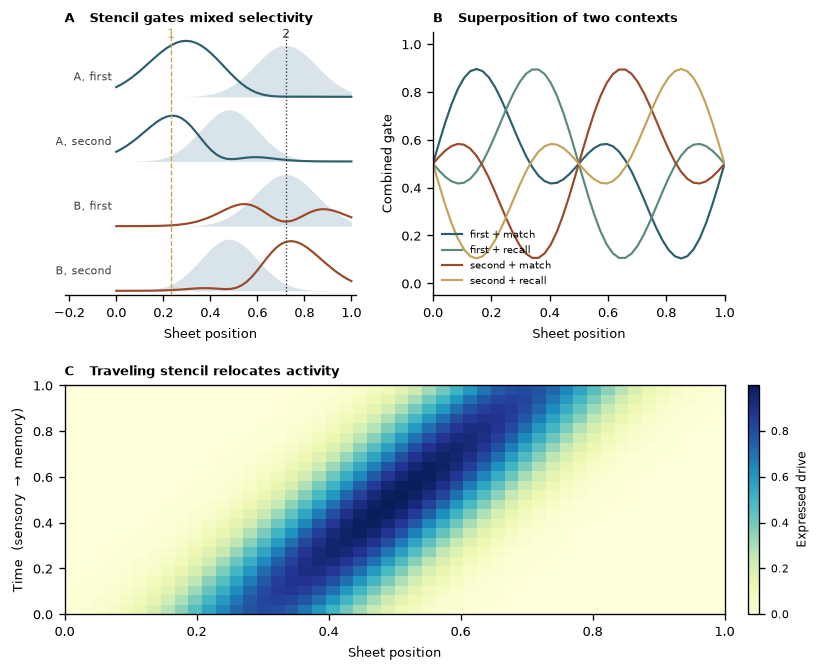

rebuild the paper PDF with: make figures


In [5]:
fig = render_paper_figure(result)
plt.show()
print("rebuild the paper PDF with: make figures")


## Follow the computation from drive to response

In the first panel, compare each original drive with the part surviving its context's stencil. Then inspect the response table at the two marked positions. A unit can look selectively responsive to an object in one context and weakly responsive in another because the multiplication changed. The original object drive and the unit's location remain fixed.

In the second panel, identify which two waves were averaged for each curve. Arithmetic averaging is sufficient to create several distinct spatial profiles. It does not explain where the waves came from or how a biological system would select them. A mechanistic account of control would need those additional dynamics.

In the traveling panel, distinguish elapsed simulation time from a fitted physiological time axis. The moving bright region reflects the prescribed open window and the fixed broad drive together. If the drive were zero at a position, an open gate would not create activity there. Predict this before changing the drive.

### Compare gating with learning and attention

Weight learning changes parameters so that future inputs are transformed differently. This example changes a state-dependent control variable while leaving the drive-generating rule fixed. Attention also changes input-dependent routing, but a similarity of gating language does not identify the same equations, signals or anatomical implementation. A useful comparison specifies what is held fixed and how the control variable is measured.

Try swapping the two suppression patterns, increasing a stencil's width or holding the traveling gate stationary. Predict which panel should change and which quantities should remain fixed. For a physiological study, ask whether a measured wave precedes the response, whether a targeted perturbation changes it and whether simpler input or gain changes explain the result. Those are follow-up questions, not outcomes of the designed curves here.


### Exercises

1. **Swap the stencils.** Hold the two object drives fixed and exchange the two context stencils. What happens to unit 2’s expressed activity? Why is that not a weight update?

<!-- solution-box: 05c_1_swap_the_stencils.py -->
<details>
<summary><strong>Show solution</strong> — Swap the stencils</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05c_1_swap_the_stencils.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.analog_waves import (
    expressed,
    run_experiment,
    selectivity_table,
)
result = run_experiment(seed=SEED)
before = selectivity_table(result)
# Exchange stencils; drives stay put.
result.stencil_first, result.stencil_second = (
    result.stencil_second,
    result.stencil_first,
)
after = selectivity_table(result)
print("unit 2 before / after swap")
for name in before:
    print(f"  {name:10s}  {before[name][1]:.3f} → {after[name][1]:.3f}")
print('The fixed control pattern changes expressed activity while the object drives and weights remain fixed. This is a designed gating calculation.')
```

</details>
<!-- /solution-box -->


2. **Subtraction is not addition.** Panel B uses the mean of two control waves. Replace the mean with the absolute difference. Do the four pairs still give four distinct spatial gates? What computation have you removed?

<!-- solution-box: 05c_2_subtraction_is_not_addition.py -->
<details>
<summary><strong>Show solution</strong> — Subtraction is not addition</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05c_2_subtraction_is_not_addition.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.analog_waves import combine_waves, control_waves, positions
x = positions()
waves = control_waves(x)
pairs = (
    ("first", "match"),
    ("first", "recall"),
    ("second", "match"),
    ("second", "recall"),
)
added = np.stack([combine_waves(waves[a], waves[b]) for a, b in pairs])
subbed = np.stack([np.abs(waves[a] - waves[b]) for a, b in pairs])

def mean_offdiag(stack):
    diffs = [np.mean(np.abs(stack[i] - stack[j]))
             for i in range(4) for j in range(i + 1, 4)]
    return float(np.mean(diffs))

print(f"mean |gate_i − gate_j|  addition     {mean_offdiag(added):.3f}")
print(f"mean |gate_i − gate_j|  |difference| {mean_offdiag(subbed):.3f}")
print('Compare the gates produced by the mean and absolute difference. These are different pointwise combination rules; neither has been fitted to physiological measurements.')
```

</details>
<!-- /solution-box -->


3. **Freeze the traveling window.** Recompute the space–time map with $\mu(t)$ held at the sensory locus. What claim about relocation is gone, and what claim about gating remains?

<!-- solution-box: 05c_3_freeze_the_window.py -->
<details>
<summary><strong>Show solution</strong> — Freeze the traveling window</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05c_3_freeze_the_window.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.analog_waves import gaussian, positions, traveling_open
x = positions()
drive = gaussian(x, 0.50, 0.32)
times = np.linspace(0.0, 1.0, 24)
moving = np.stack([drive * traveling_open(x, t) for t in times])
frozen = np.stack([drive * traveling_open(x, 0.0) for _ in times])
peak_move = x[np.argmax(moving, axis=1)]
peak_frz = x[np.argmax(frozen, axis=1)]
print(f"moving  peak x: {peak_move[0]:.2f} → {peak_move[-1]:.2f}")
print(f"frozen  peak x: {peak_frz[0]:.2f} → {peak_frz[-1]:.2f}")
print('Freezing the window retains static gating but removes translation. Compare the space-time maps to identify the contribution of the moving control pattern.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What is specified rather than learned in the stencil example?

2. What does combining two gates demonstrate?

3. What does moving the open window change?

4. How does this relate to Transformer attention?

5. What biological evidence would support the analogy?


### Further reading

1. **Miller, E. K., Brincat, S. L., and Roy, J. E. (2026).** [*Analog Cognition and Consciousness*](https://doi.org/10.1523/JNEUROSCI.0711-26.2026). *J. Neurosci.* 46(33):e0711262026.
2. **Hopfield, J. J. (1982).** [*Neural networks and physical systems with emergent collective computational abilities*](https://redwood.berkeley.edu/wp-content/uploads/2018/08/hopfield82.pdf). *PNAS* 79(8), 2554–2558.
3. **Block, N. (1995).** [*On a confusion about a function of consciousness*](https://divinecuration.github.io/assets/pdf/block-confusion.pdf). *Behavioral and Brain Sciences* 18(2), 227–247.
4. **Dehaene, S. (2014).** [*Consciousness and the Brain*](https://www.penguinrandomhouse.com/books/310548/consciousness-and-the-brain-by-stanislas-dehaene/). Viking.
